# Phase 6 — Drawdowns historiques et risque

Le drawdown mesure la baisse du niveau de clôture par rapport à son sommet antérieur. Il est calculé directement à partir de la trajectoire des prix.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
prices = pd.read_csv(ROOT / 'data/processed/sp500_prices.csv', index_col='date', parse_dates=True).close
prices.head()

date
2016-09-06    2186.479980
2016-09-07    2186.159912
2016-09-08    2181.300049
2016-09-09    2127.810059
2016-09-12    2159.040039
Name: close, dtype: float64

## 1. Exemple numérique du drawdown

Pour une trajectoire de prix de 100 à 120 puis à 90, la baisse depuis le sommet vaut `90 / 120 − 1 = −25 %`.

In [2]:
example = pd.DataFrame({'close':[100.,120.,90.,110.,120.]})
example['running_peak'] = example.close.cummax()
example['drawdown'] = example.close/example.running_peak - 1
example

,close,running_peak,drawdown
0,100.0,100.0,0.000000
1,120.0,120.0,0.000000
2,90.0,120.0,-0.250000
3,110.0,120.0,-0.083333
4,120.0,120.0,0.000000


## 2. Calcul et vérification du drawdown du S&P 500

Les drawdowns sont négatifs ou nuls. Le minimum correspond à la plus forte baisse observée depuis un sommet antérieur.

In [3]:
calculated = prices/prices.cummax()-1
saved = pd.read_csv(ROOT / 'data/risk/sp500_drawdowns.csv', index_col='date', parse_dates=True)
np.testing.assert_allclose(calculated, saved.drawdown, atol=1e-14)
print(f'Maximum drawdown: {calculated.min():.2%}')
print('Trough date:', calculated.idxmin().date())

Maximum drawdown: -33.92%
Trough date: 2020-03-23


## 3. Comparaison des trois indices

La récupération correspond à la première clôture ultérieure atteignant le sommet de référence. Les durées sont exprimées en jours calendaires.

In [4]:
summary = pd.read_csv(ROOT / 'reports/phase6_drawdown_summary.csv')
summary[['index','maximum_drawdown','peak_date','trough_date','recovery_date','peak_to_recovery_calendar_days']]

,index,maximum_drawdown,peak_date,trough_date,recovery_date,peak_to_recovery_calendar_days
0,S&P 500,-0.339250,2020-02-19,2020-03-23,2020-08-18,181
1,CAC 40,-0.385585,2020-02-19,2020-03-18,2021-04-06,412
2,FTSE 100,-0.366055,2018-05-22,2020-03-23,2023-02-03,1718


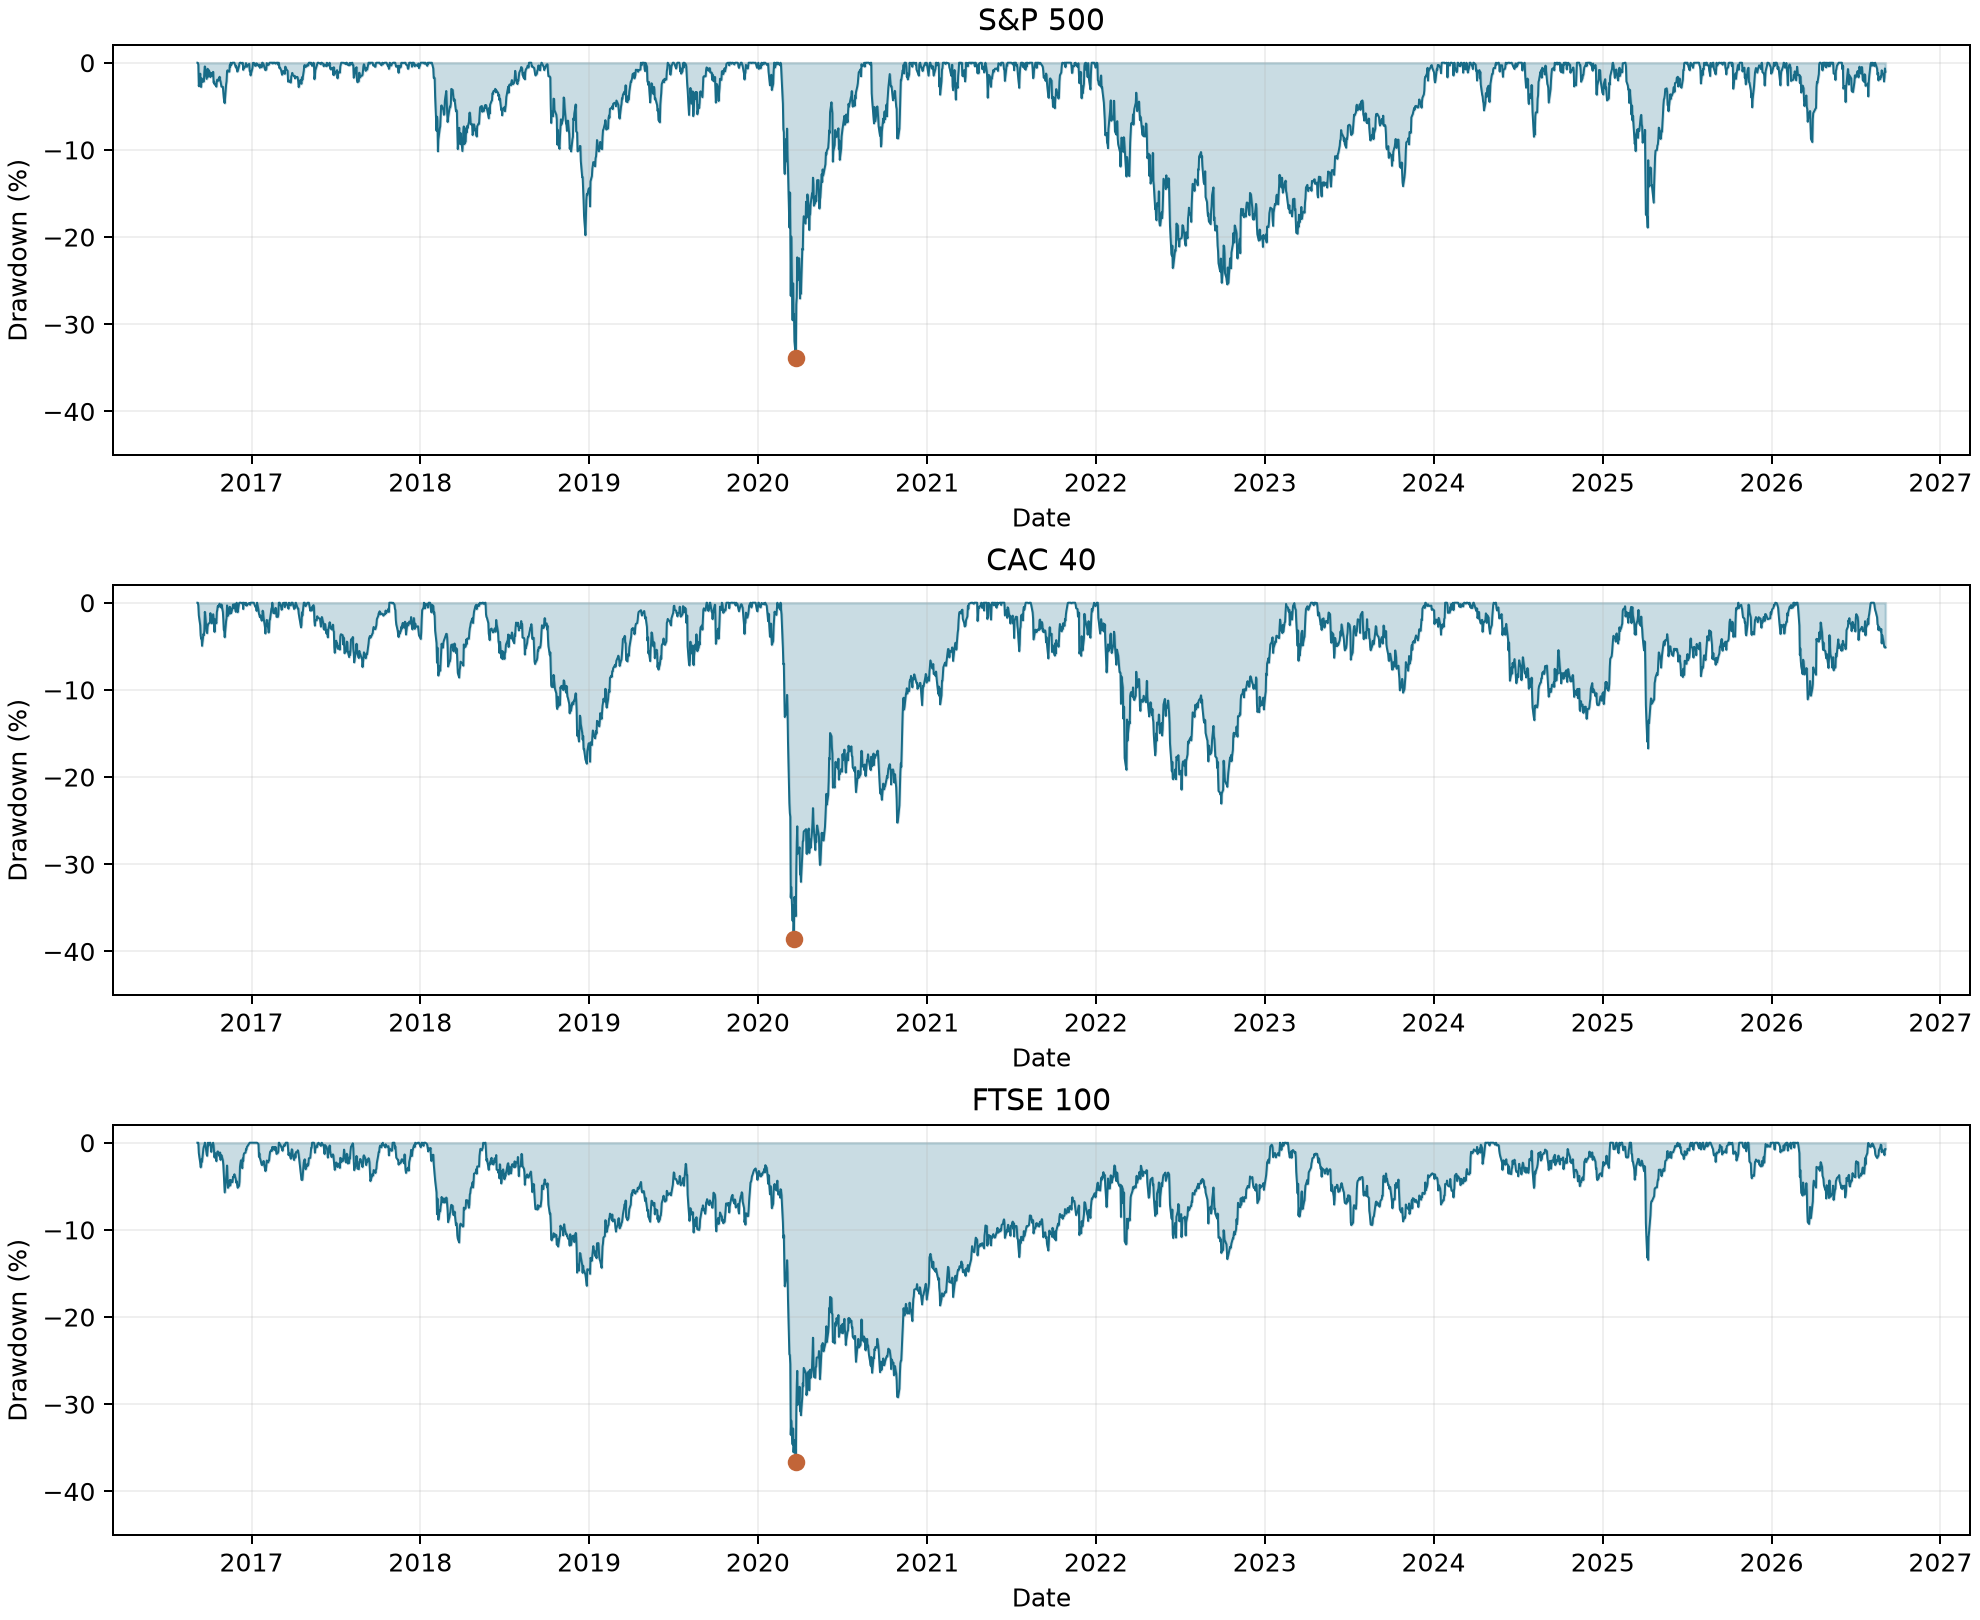

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/phase6_drawdowns.png')))

## 4. Interprétation des résultats

Le sommet de référence du FTSE date de mai 2018 : sa baisse complète ne se concentre pas en mars 2020. La volatilité, la baisse maximale et la durée de récupération décrivent des dimensions différentes du risque. Les résultats portent sur les clôtures historiques, sans dividendes réinvestis ni conversion de devises.

## 5. Incidence de la clôture FTSE manquante

La clôture manquante de décembre 2020 reste indisponible. Les drawdowns ultérieurs utilisent le plus haut cours antérieur observé. Un éventuel extrême à la date manquante ne peut pas être mesuré.

In [6]:
ftse = pd.read_csv(ROOT / 'data/risk/ftse100_drawdowns.csv', index_col='date', parse_dates=True)
ftse.loc['2020-12-18':'2020-12-24']

,close,running_peak,drawdown
date,,,
2020-12-18,6529.200195,7877.5,-0.171158
2020-12-21,6416.299805,7877.5,-0.185490
2020-12-23,6495.799805,7877.5,-0.175398
2020-12-24,6502.100098,7877.5,-0.174599
